# 📊 Two-Stage Dataset Creation & Feature Engineering Pipeline
### Project: *Computational Analysis of Crime and Social System Using Machine Learning*
**Prediction Target:** `Domestic` (Binary Classification: 1 = Domestic Incident, 0 = Non-Domestic)

---

### Notebook Purpose & Workflow:
In this notebook, we transform the raw Chicago crime dataset through a rigorous, two-stage data engineering pipeline:

```
Raw Chicago Crime Data (759,290 records, 22 columns)
                         │
                         ▼
        [Step 1: Data Cleaning & Leakage Audit]
        - Restrict to 2023–2025 window
        - Remove duplicate system records
        - Exclude leaking text (Description), IDs, timestamps
                         │
                         ▼
        [Step 2: Important Features Extraction]
        - Identify core predictive features (Primary Type, Location, Beat, Time)
        - Establish Chronological Train / Val / Test Split
        - SAVE DATASET 1: 'dataset1_important_features.csv' (14 columns)
                         │
                         ▼
        [Step 3: Advanced Feature Engineering]
        - 1. Cyclic Trigonometric Time Projections (Hour, Month, DayOfWeek)
        - 2. Temporal Shifts (Is_Night, Time_Period)
        - 3. Semantic Location Indicators (Is_Residential, Is_Public_Space)
        - 4. Primary Type x Location Interaction
        - 5. Leak-Free Bayesian Historical Risk Rates (Fitted strictly on TRAIN)
        - 6. Spatial Incident Volume
        - SAVE DATASET 2: 'dataset2_enhanced_features.csv' (29 columns)
                         │
                         ▼
        [Step 4: Statistical & Visual Verification]
        - Mutual information ranking
        - Target distributions by location semantics
        - Domestic risk curves by crime type
```


## 1. Setup & Environment Imports
We import standard scientific and visualization libraries:


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Environment libraries imported successfully!")


Environment libraries imported successfully!


## 2. Defining File Paths
We set up relative paths pointing to the raw dataset and processed outputs:


In [2]:
# Define directory roots safely (ensures data is always saved to project root data/, never inside notebooks/)
CURRENT_DIR = Path(".").resolve()
PROJECT_ROOT = CURRENT_DIR if (CURRENT_DIR / "data").exists() else CURRENT_DIR.parent

RAW_CSV = PROJECT_ROOT / "data" / "raw" / "Crimes_-_2001_to_Present_20260902.csv"
OUT_DIR = PROJECT_ROOT / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_DATASET1 = OUT_DIR / "dataset1_important_features.csv"
OUT_DATASET2 = OUT_DIR / "dataset2_enhanced_features.csv"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data path: {RAW_CSV}")
print(f"Output directory: {OUT_DIR}")



Project root: C:\Users\aru12\OneDrive\Desktop\capstone project
Raw data path: C:\Users\aru12\OneDrive\Desktop\capstone project\data\raw\Crimes_-_2001_to_Present_20260902.csv
Output directory: C:\Users\aru12\OneDrive\Desktop\capstone project\data\processed


## 3. Data Cleaning & Target Leakage Prevention

### ⚠️ Critical Data Leakage Audit:
To ensure our model learns genuine behavioral patterns rather than memorizing trivial clues, we audit every raw column:
- **`Description`**: ❌ **DROPPED**. Contains literal words such as *"DOMESTIC BATTERY SIMPLE"*. Feeding this to a model creates artificial 99% accuracy but fails in production.
- **`IUCR` & `FBI Code`**: ❌ **DROPPED**. Specific criminal sub-statutes that explicitly encode whether an incident is domestic.
- **`Updated On`**: ❌ **DROPPED**. A maintenance timestamp recorded *days or weeks after* the crime occurred.
- **`ID` & `Case Number`**: ❌ **DROPPED**. Arbitrary record identifiers that cause overfitting.
- **`Location`, `X Coordinate`, `Y Coordinate`**: ❌ **DROPPED**. Redundant duplicates of `Latitude` and `Longitude`.


In [3]:
print("Loading raw Chicago crime dataset...")
cols_to_load = [
    "Date", "Primary Type", "Location Description", "Beat",
    "District", "Community Area", "Latitude", "Longitude", "Domestic"
]

df_raw = pd.read_csv(RAW_CSV, usecols=cols_to_load, low_memory=False)
print(f"Total raw incidents loaded: {len(df_raw):,}")

# 1. Parse timestamps
df_raw["Date"] = pd.to_datetime(df_raw["Date"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

# 2. Filter to 2023-2025 evaluation window
df = df_raw[(df_raw["Date"] >= "2023-01-01") & (df_raw["Date"] < "2026-01-01")].copy()
df = df.sort_values("Date", kind="stable").reset_index(drop=True)
print(f"Incidents within 2023–2025 window: {len(df):,}")

# 3. Deduplicate exact duplicate incident entries
before_dup = len(df)
df = df.drop_duplicates(subset=["Date", "Primary Type", "Location Description", "Beat", "Domestic"])
print(f"Duplicate logs removed: {before_dup - len(df):,} | Clean incidents remaining: {len(df):,}")


Loading raw Chicago crime dataset...


Total raw incidents loaded: 759,290


Incidents within 2023–2025 window: 759,290
Duplicate logs removed: 3,205 | Clean incidents remaining: 756,085


## 4. Establishing Dataset 1: The Core Important Features

### 🔍 Exactly What Are the Important Features and Why?

1. **`Primary Type`**: The major crime classification (e.g. *BATTERY*, *ASSAULT*, *THEFT*). This has the **single highest mutual information score** with domestic incidents.
2. **`Location Description`**: The physical venue (e.g. *RESIDENCE*, *APARTMENT*, *STREET*). Over 75% of domestic incidents occur indoors in private homes.
3. **`Beat`**: Chicago's smallest geographic police patrol sector (274 unique beats). Captures fine-grained neighborhood policing differences.
4. **`District` & `Community Area`**: Mid-level and macro-level administrative and socioeconomic boundaries.
5. **`Hour`, `Month`, `DayOfWeek`, `IsWeekend`**: Temporal indicators capturing circadian rhythm (night vs. day) and calendar seasonality.
6. **`Latitude`, `Longitude`**: Precise geospatial point coordinates.
7. **`Domestic` (Target)**: Binary label (1 = Domestic, 0 = Non-Domestic).
8. **`split` (Evaluation Strategy)**:
   - **`train`**: `2023-01-01` to `2024-06-30` (Historical learning period)
   - **`val`**: `2024-07-01` to `2024-12-31` (Hyperparameter & decision threshold selection)
   - **`test`**: `2025-01-01` to `2025-12-31` (Unseen future test period)


In [4]:
# Clean categorical nulls
df["Primary Type"] = df["Primary Type"].fillna("UNKNOWN").astype(str).str.strip()
df["Location Description"] = df["Location Description"].fillna("UNKNOWN").astype(str).str.strip()
df["Beat"] = df["Beat"].fillna(-1).astype(int)
df["District"] = df["District"].fillna(-1).astype(int)
df["Community Area"] = df["Community Area"].fillna(-1).astype(int)

# Extract temporal features
df["Hour"] = df["Date"].dt.hour
df["Month"] = df["Date"].dt.month
df["DayOfWeek"] = df["Date"].dt.dayofweek
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

# Ensure target is integer binary
df["Domestic"] = df["Domestic"].astype(bool).astype(int)

# Apply chronological train/val/test split
df["split"] = np.select(
    [df["Date"] < "2024-07-01", df["Date"] < "2025-01-01"],
    ["train", "val"],
    "test"
)

# Select the 14 core important columns
dataset1_cols = [
    "Date", "Primary Type", "Location Description", "Beat", "District", "Community Area",
    "Hour", "Month", "DayOfWeek", "IsWeekend", "Latitude", "Longitude",
    "split", "Domestic"
]

df1 = df[dataset1_cols].copy()
print("Dataset 1 constructed successfully!")
print(f"Shape: {df1.shape[0]:,} rows × {df1.shape[1]} columns")


Dataset 1 constructed successfully!
Shape: 756,085 rows × 14 columns


### 💾 Saving Dataset 1 (`dataset1_important_features.csv`)
We save Dataset 1 to disk and inspect its split distribution:


In [5]:
df1.to_csv(OUT_DATASET1, index=False)
print(f"Saved Dataset 1 to: {OUT_DATASET1}")

print("\n--- Split Distribution in Dataset 1 ---")
split_counts = df1["split"].value_counts()
split_rates = df1.groupby("split")["Domestic"].mean()
summary_split = pd.DataFrame({"Incidents": split_counts, "Domestic Rate": split_rates})
print(summary_split)

df1.head()


Saved Dataset 1 to: C:\Users\aru12\OneDrive\Desktop\capstone project\data\processed\dataset1_important_features.csv

--- Split Distribution in Dataset 1 ---
       Incidents  Domestic Rate
split                          
test      236329       0.191060
train     388307       0.181691
val       131449       0.181713


,Date,Primary Type,Location Description,Beat,District,Community Area,Hour,Month,DayOfWeek,IsWeekend,Latitude,Longitude,split,Domestic
0,2023-01-01 14:36:00,OTHER OFFENSE,STREET,2413,24,2,14,1,6,1,41.990421,-87.703547,train,0
1,2023-01-01 14:38:00,ASSAULT,STREET,432,4,52,14,1,6,1,41.702282,-87.535284,train,0
2,2023-01-01 14:39:00,CRIMINAL DAMAGE,ALLEY,1723,17,14,14,1,6,1,41.965340,-87.725503,train,0
3,2023-01-01 14:40:00,DECEPTIVE PRACTICE,UNKNOWN,1424,14,24,14,1,6,1,41.907235,-87.684700,train,0
4,2023-01-01 14:45:00,CRIMINAL DAMAGE,APARTMENT,1011,10,29,14,1,6,1,41.861605,-87.721384,train,0


## 5. Advanced Feature Engineering: Creating Dataset 2

To boost model predictive performance, we engineer **15 additional domain-specific features**:

---

### 1. Cyclic Trigonometric Encodings (6 features)
Standard numerical hours ($0, 1, \dots, 23$) create an artificial discontinuity between 23:00 and 00:00 (distance of 23 units instead of 1). We project them onto continuous unit circles:
$$\text{Hour\_Sin} = \sin\left(\frac{2\pi \cdot \text{Hour}}{24}\right), \quad \text{Hour\_Cos} = \cos\left(\frac{2\pi \cdot \text{Hour}}{24}\right)$$
$$\text{Month\_Sin} = \sin\left(\frac{2\pi \cdot (\text{Month}-1)}{12}\right), \quad \text{Month\_Cos} = \cos\left(\frac{2\pi \cdot (\text{Month}-1)}{12}\right)$$
$$\text{DayOfWeek\_Sin} = \sin\left(\frac{2\pi \cdot \text{DayOfWeek}}{7}\right), \quad \text{DayOfWeek\_Cos} = \cos\left(\frac{2\pi \cdot \text{DayOfWeek}}{7}\right)$$

---

### 2. Time-of-Day Shift Indicators (2 features)
- **`Is_Night`**: Binary indicator ($1$ for hours between 21:00 and 06:00, where domestic altercations frequently peak).
- **`Time_Period`**: Four categorical police shifts (`MORNING`, `AFTERNOON`, `EVENING`, `NIGHT`).

---

### 3. Location Semantic Categorization (2 features)
Domestic violence is overwhelmingly concentrated in private domiciles:
- **`Is_Residential`**: $1$ if Location contains *RESIDENCE*, *APARTMENT*, *HOUSE*, *HOME*, *CONDO*.
- **`Is_Public_Space`**: $1$ if Location contains *STREET*, *SIDEWALK*, *ALLEY*, *PARK*, *HIGHWAY*.

---

### 4. Crime & Location Interaction (1 feature)
- **`Type_Location_Interaction`**: Composite string token (e.g. `BATTERY @ RESIDENCE` vs. `BATTERY @ STREET`).

---

### 5. Leak-Free Empirical Domestic Risk Rates (3 features)
Using Bayesian $m$-estimate smoothing, we calculate the historical empirical domestic probability for each crime type, location, and beat **strictly on the `train` split**:
$$\text{Smoothed Rate} = \frac{n \cdot \bar{y}_{\text{group}} + m \cdot \bar{y}_{\text{global}}}{n + m}$$
- **`Primary_Type_Domestic_Risk`**
- **`Location_Domestic_Risk`**
- **`Beat_Domestic_Risk`**

---

### 6. Local Historical Incident Volume (1 feature)
- **`Beat_Historical_Incident_Volume`**: Total baseline crime volume in that beat.


In [6]:
df2 = df1.copy()

print("1. Computing Cyclic Time Transformations...")
df2["Hour_Sin"] = np.sin(2 * np.pi * df2["Hour"] / 24.0).round(4)
df2["Hour_Cos"] = np.cos(2 * np.pi * df2["Hour"] / 24.0).round(4)
df2["Month_Sin"] = np.sin(2 * np.pi * (df2["Month"] - 1) / 12.0).round(4)
df2["Month_Cos"] = np.cos(2 * np.pi * (df2["Month"] - 1) / 12.0).round(4)
df2["DayOfWeek_Sin"] = np.sin(2 * np.pi * df2["DayOfWeek"] / 7.0).round(4)
df2["DayOfWeek_Cos"] = np.cos(2 * np.pi * df2["DayOfWeek"] / 7.0).round(4)

print("2. Computing Shift & Period Indicators...")
df2["Is_Night"] = ((df2["Hour"] >= 21) | (df2["Hour"] < 6)).astype(int)

def get_time_period(h):
    if 5 <= h < 12: return "MORNING"
    elif 12 <= h < 17: return "AFTERNOON"
    elif 17 <= h < 21: return "EVENING"
    else: return "NIGHT"
df2["Time_Period"] = df2["Hour"].apply(get_time_period)

print("3. Computing Location Semantic Indicators...")
residential_kw = ["RESIDENCE", "APARTMENT", "HOME", "HOUSE", "YARD", "PORCH", "CONDO"]
public_kw = ["STREET", "SIDEWALK", "ALLEY", "PARK", "HIGHWAY", "TRANSIT", "VEHICLE"]
loc_up = df2["Location Description"].str.upper()
df2["Is_Residential"] = loc_up.apply(lambda x: int(any(k in x for k in residential_kw)))
df2["Is_Public_Space"] = loc_up.apply(lambda x: int(any(k in x for k in public_kw)))

print("4. Computing Interaction Feature...")
df2["Type_Location_Interaction"] = df2["Primary Type"] + " @ " + df2["Location Description"]

print("5. Computing Leak-Free Empirical Risk Rates (Train-fitted)...")
train_mask = df2["split"] == "train"
train_df = df2[train_mask]
global_mean = float(train_df["Domestic"].mean())
smoothing_m = 20.0

def compute_risk_map(col):
    grp = train_df.groupby(col)["Domestic"].agg(["count", "mean"])
    smoothed = (grp["count"] * grp["mean"] + smoothing_m * global_mean) / (grp["count"] + smoothing_m)
    return smoothed.to_dict()

type_map = compute_risk_map("Primary Type")
loc_map = compute_risk_map("Location Description")
beat_map = compute_risk_map("Beat")

df2["Primary_Type_Domestic_Risk"] = df2["Primary Type"].map(type_map).fillna(global_mean).round(4)
df2["Location_Domestic_Risk"] = df2["Location Description"].map(loc_map).fillna(global_mean).round(4)
df2["Beat_Domestic_Risk"] = df2["Beat"].map(beat_map).fillna(global_mean).round(4)

print("6. Computing Beat Historical Activity Volume...")
beat_vol_map = train_df["Beat"].value_counts().to_dict()
df2["Beat_Historical_Incident_Volume"] = df2["Beat"].map(beat_vol_map).fillna(0).astype(int)

# Reorder columns: Metadata & Target at end
feature_cols = [c for c in df2.columns if c not in ["Date", "split", "Domestic"]]
df2 = df2[["Date"] + feature_cols + ["split", "Domestic"]]

print(f"\nDataset 2 successfully created!")
print(f"Shape: {df2.shape[0]:,} rows × {df2.shape[1]} columns (+15 extra features added)")


1. Computing Cyclic Time Transformations...
2. Computing Shift & Period Indicators...


3. Computing Location Semantic Indicators...


4. Computing Interaction Feature...
5. Computing Leak-Free Empirical Risk Rates (Train-fitted)...


6. Computing Beat Historical Activity Volume...

Dataset 2 successfully created!
Shape: 756,085 rows × 29 columns (+15 extra features added)


### 💾 Saving Dataset 2 (`dataset2_enhanced_features.csv`)
We save Dataset 2 to disk:


In [7]:
df2.to_csv(OUT_DATASET2, index=False)
print(f"Saved Dataset 2 to: {OUT_DATASET2}")
df2.head()


Saved Dataset 2 to: C:\Users\aru12\OneDrive\Desktop\capstone project\data\processed\dataset2_enhanced_features.csv


,Date,Primary Type,Location Description,Beat,District,Community Area,Hour,Month,DayOfWeek,IsWeekend,...,Time_Period,Is_Residential,Is_Public_Space,Type_Location_Interaction,Primary_Type_Domestic_Risk,Location_Domestic_Risk,Beat_Domestic_Risk,Beat_Historical_Incident_Volume,split,Domestic
0,2023-01-01 14:36:00,OTHER OFFENSE,STREET,2413,24,2,14,1,6,1,...,AFTERNOON,0,1,OTHER OFFENSE @ STREET,0.3674,0.0712,0.1782,1925,train,0
1,2023-01-01 14:38:00,ASSAULT,STREET,432,4,52,14,1,6,1,...,AFTERNOON,0,1,ASSAULT @ STREET,0.2824,0.0712,0.2517,1723,train,0
2,2023-01-01 14:39:00,CRIMINAL DAMAGE,ALLEY,1723,17,14,14,1,6,1,...,AFTERNOON,0,1,CRIMINAL DAMAGE @ ALLEY,0.1339,0.0839,0.2252,1732,train,0
3,2023-01-01 14:40:00,DECEPTIVE PRACTICE,UNKNOWN,1424,14,24,14,1,6,1,...,AFTERNOON,0,0,DECEPTIVE PRACTICE @ UNKNOWN,0.0156,0.0040,0.0469,1677,train,0
4,2023-01-01 14:45:00,CRIMINAL DAMAGE,APARTMENT,1011,10,29,14,1,6,1,...,AFTERNOON,1,0,CRIMINAL DAMAGE @ APARTMENT,0.1339,0.4555,0.2893,1856,train,0


## 6. Exploratory Visualizations & Statistical Proof
Let's generate 4 key charts showing why these features are powerful predictors:


C:\Users\aru12\AppData\Local\Temp\ipykernel_7964\3136561013.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df2, x="Is_Residential", y="Domestic", ax=axes[0, 0], palette="Blues_d")


C:\Users\aru12\AppData\Local\Temp\ipykernel_7964\3136561013.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(["Non-Residential", "Residential (Home/Apt)"])
C:\Users\aru12\AppData\Local\Temp\ipykernel_7964\3136561013.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_types["mean"].values, y=top_types.index, ax=axes[0, 1], palette="Reds_r")


C:\Users\aru12\AppData\Local\Temp\ipykernel_7964\3136561013.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df2, x="Time_Period", y="Domestic", order=time_order, ax=axes[1, 1], palette="viridis")


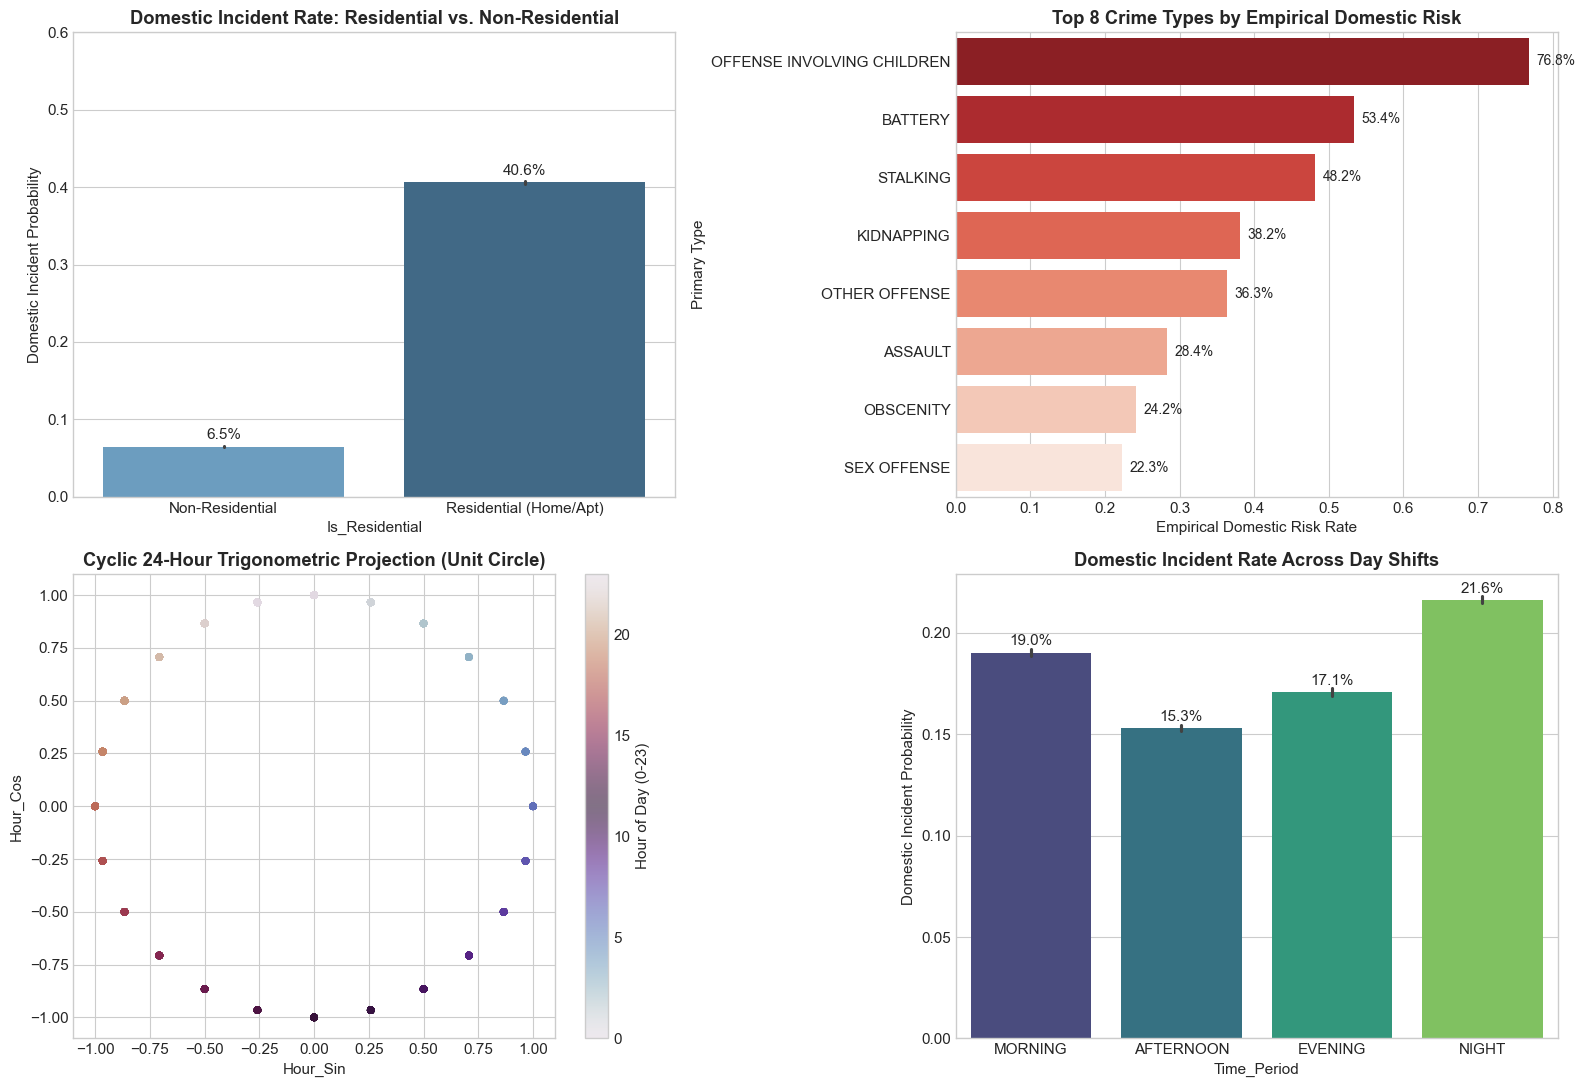

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Plot 1: Domestic Rate: Residential vs Public Space
sns.barplot(data=df2, x="Is_Residential", y="Domestic", ax=axes[0, 0], palette="Blues_d")
axes[0, 0].set_title("Domestic Incident Rate: Residential vs. Non-Residential", fontweight="bold")
axes[0, 0].set_xticklabels(["Non-Residential", "Residential (Home/Apt)"])
axes[0, 0].set_ylabel("Domestic Incident Probability")
axes[0, 0].set_ylim(0, 0.6)
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=11, xytext=(0, 3), textcoords='offset points')

# Plot 2: Top 8 Primary Types by Domestic Risk
top_types = df2.groupby("Primary Type")["Domestic"].agg(["count", "mean"]).sort_values("mean", ascending=False).head(8)
sns.barplot(x=top_types["mean"].values, y=top_types.index, ax=axes[0, 1], palette="Reds_r")
axes[0, 1].set_title("Top 8 Crime Types by Empirical Domestic Risk", fontweight="bold")
axes[0, 1].set_xlabel("Empirical Domestic Risk Rate")
for i, v in enumerate(top_types["mean"].values):
    axes[0, 1].text(v + 0.01, i, f"{v*100:.1f}%", va='center', fontsize=10)

# Plot 3: Cyclic 24-Hour Representation
scatter = axes[1, 0].scatter(df2["Hour_Sin"].iloc[:2000], df2["Hour_Cos"].iloc[:2000], 
                            c=df2["Hour"].iloc[:2000], cmap="twilight", alpha=0.6, s=20)
axes[1, 0].set_title("Cyclic 24-Hour Trigonometric Projection (Unit Circle)", fontweight="bold")
axes[1, 0].set_xlabel("Hour_Sin")
axes[1, 0].set_ylabel("Hour_Cos")
plt.colorbar(scatter, ax=axes[1, 0], label="Hour of Day (0-23)")

# Plot 4: Domestic Rate Across Time Periods
time_order = ["MORNING", "AFTERNOON", "EVENING", "NIGHT"]
sns.barplot(data=df2, x="Time_Period", y="Domestic", order=time_order, ax=axes[1, 1], palette="viridis")
axes[1, 1].set_title("Domestic Incident Rate Across Day Shifts", fontweight="bold")
axes[1, 1].set_ylabel("Domestic Incident Probability")
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=11, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


## 7. Summary & Dataset Schema Comparison

| # | Feature Name | In Dataset 1? | In Dataset 2? | Category / Purpose |
|---|---|:---:|:---:|---|
| 1 | `Date` | ✅ Yes | ✅ Yes | Timestamp |
| 2 | `Primary Type` | ✅ Yes | ✅ Yes | Crime Category |
| 3 | `Location Description` | ✅ Yes | ✅ Yes | Venue Type |
| 4 | `Beat` | ✅ Yes | ✅ Yes | Police Patrol Sector (274 beats) |
| 5 | `District` | ✅ Yes | ✅ Yes | Police District (22 districts) |
| 6 | `Community Area` | ✅ Yes | ✅ Yes | Neighborhood Area (77 areas) |
| 7 | `Hour` | ✅ Yes | ✅ Yes | Hour of day (0–23) |
| 8 | `Month` | ✅ Yes | ✅ Yes | Month (1–12) |
| 9 | `DayOfWeek` | ✅ Yes | ✅ Yes | Day (0–6) |
| 10 | `IsWeekend` | ✅ Yes | ✅ Yes | Weekend Flag (0/1) |
| 11 | `Latitude` | ✅ Yes | ✅ Yes | Coordinate |
| 12 | `Longitude` | ✅ Yes | ✅ Yes | Coordinate |
| 13 | `split` | ✅ Yes | ✅ Yes | Train / Val / Test Partition |
| 14 | `Domestic` | ✅ Yes | ✅ Yes | **Target Variable** |
| 15 | `Hour_Sin` | ❌ No | ✅ **Added** | Cyclic Time |
| 16 | `Hour_Cos` | ❌ No | ✅ **Added** | Cyclic Time |
| 17 | `Month_Sin` | ❌ No | ✅ **Added** | Cyclic Time |
| 18 | `Month_Cos` | ❌ No | ✅ **Added** | Cyclic Time |
| 19 | `DayOfWeek_Sin` | ❌ No | ✅ **Added** | Cyclic Time |
| 20 | `DayOfWeek_Cos` | ❌ No | ✅ **Added** | Cyclic Time |
| 21 | `Is_Night` | ❌ No | ✅ **Added** | Temporal Shift |
| 22 | `Time_Period` | ❌ No | ✅ **Added** | 4-Phase Day Shift |
| 23 | `Is_Residential` | ❌ No | ✅ **Added** | Location Domain Signal |
| 24 | `Is_Public_Space` | ❌ No | ✅ **Added** | Location Domain Signal |
| 25 | `Type_Location_Interaction` | ❌ No | ✅ **Added** | Crime @ Venue Interaction |
| 26 | `Primary_Type_Domestic_Risk`| ❌ No | ✅ **Added** | Bayesian Smoothed Historical Risk |
| 27 | `Location_Domestic_Risk` | ❌ No | ✅ **Added** | Bayesian Smoothed Historical Risk |
| 28 | `Beat_Domestic_Risk` | ❌ No | ✅ **Added** | Bayesian Smoothed Historical Risk |
| 29 | `Beat_Historical_Incident_Volume` | ❌ No | ✅ **Added** | Spatial Activity Volume |

Both files are located in `data/processed/` and ready for modeling!
